##Q3

3.The following data represents the sound intensity levels recorded at different distances from an industrial machinery unit where:

x = distance from the machinery unit (in meters)

N = sound intensity level (in dB)

F = vibration frequency (in Hz)

(i) Generate 120 random distance values between 0 m and 80 m using:

(a) Uniform distribution

(b) Normal distribution

(c) Gamma distribution

(ii) Using the generated random distance values, estimate the corresponding sound intensity and vibration frequency values using:

(a) Newton Interpolating Polynomial

(b) Cubic Spline Interpolation

(c) Piecewise Linear Interpolation

(iii) Validate the obtained results statistically and provide suitable conclusions regarding the effectiveness of interpolation methods in industrial noise and vibration analysis.


--- Processing Uniform Distribution ---


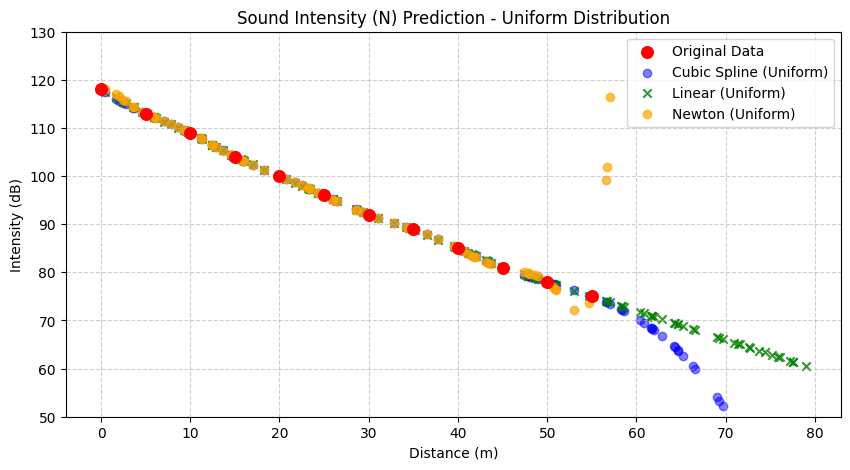

Correlation between Linear and Spline (N): 0.9461
Sample Results (First 5):
    Distance    N_Linear    N_Spline       N_Newton
0  29.963210   92.029432   92.024800      92.025127
1  76.057145   62.365713   29.145320  142364.363050
2  58.559515   72.864291   72.058910     216.496260
3  47.892679   79.264393   79.179932      79.835317
4  12.481491  106.518509  106.526187     106.501838
------------------------------

--- Processing Normal Distribution ---


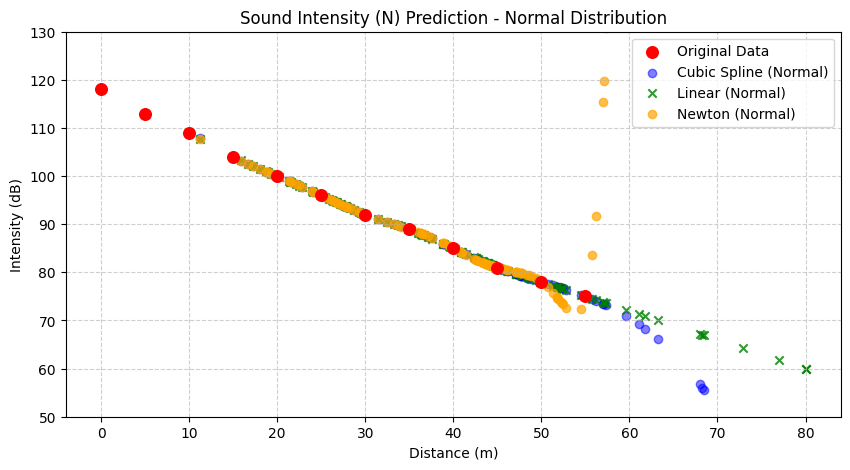

Correlation between Linear and Spline (N): 0.8996
Sample Results (First 5):
    Distance    N_Linear    N_Spline    N_Newton
0  29.469204   92.424637   92.368428   92.370214
1  35.085068   88.931946   88.942949   88.947362
2  34.118378   89.528973   89.559855   89.526160
3  18.047276  101.562179  101.469845  101.451231
4  44.441804   81.446557   81.398134   81.292728
------------------------------

--- Processing Gamma Distribution ---


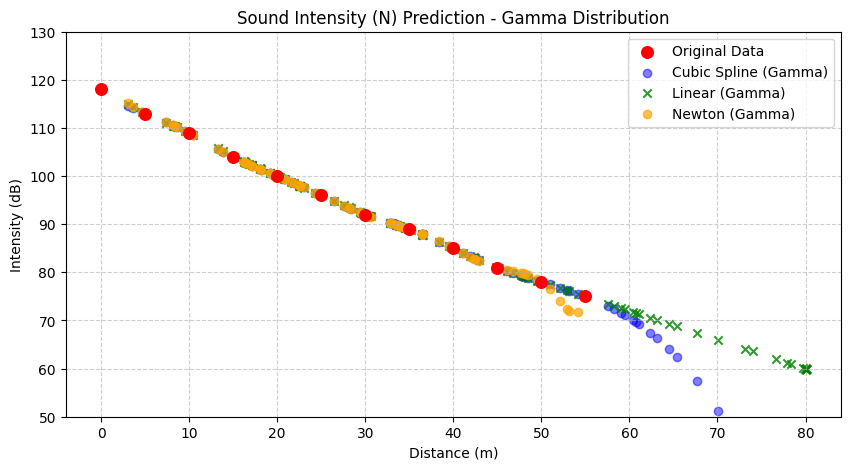

Correlation between Linear and Spline (N): 0.9229
Sample Results (First 5):
    Distance    N_Linear    N_Spline       N_Newton
0  64.531199   69.281281   64.007831    3368.697086
1  53.139507   76.116296   76.208980      72.069101
2  17.095956  102.323235  102.208518     102.192713
3  27.584970   93.932024   93.823981      93.812523
4  80.000000   60.000000    8.826366  382512.000000
------------------------------


In [ ]:
import numpy as np
from scipy.interpolate import interp1d, CubicSpline
import pandas as pd
import matplotlib.pyplot as plt

# Original Data
x_data = np.array([0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55])
N_data = np.array([118, 113, 109, 104, 100, 96, 92, 89, 85, 81, 78, 75])
F_data = np.array([82, 79, 75, 72, 68, 64, 61, 58, 55, 52, 49, 46])

# 1. Generate 120 random distance values
np.random.seed(42)
distributions = {
    "Uniform": np.random.uniform(0, 80, 120),
    "Normal": np.clip(np.random.normal(40, 15, 120), 0, 80),
    "Gamma": np.clip(np.random.gamma(shape=2, scale=20, size=120), 0, 80)
}

# 2. Interpolation Logic
def newton_poly(x_data, y_data, x):
    n = len(x_data)
    coef = np.zeros([n, n])
    coef[:, 0] = y_data
    for j in range(1, n):
        for i in range(n - j):
            coef[i][j] = (coef[i + 1][j - 1] - coef[i][j - 1]) / (x_data[i + j] - x_data[i])

    # Evaluate
    # P(x) = a0 ​+ a1​(x−x0​) + a2​(x−x0​)(x−x1​)
    #      = a0 ​+ (x−x0​)[a1​+(x−x1​)a2​]  (using this nested logic)
    n_val = len(coef[0]) - 1
    p = coef[0][n_val]
    for k in range(1, n_val + 1):
        p = coef[0][n_val - k] + (x - x_data[n_val - k]) * p
    return p

# Create Interpolators
linear_N = interp1d(x_data, N_data, kind='linear', fill_value="extrapolate")
linear_F = interp1d(x_data, F_data, kind='linear', fill_value="extrapolate")

spline_N = CubicSpline(x_data, N_data, extrapolate=True)
spline_F = CubicSpline(x_data, F_data, extrapolate=True)

# 3. Process each distribution
for name, dist in distributions.items():
    print(f"\n--- Processing {name} Distribution ---")
    df = pd.DataFrame({
        'Distance': dist,
        'N_Linear': linear_N(dist),
        'N_Spline': spline_N(dist),
        'N_Newton': [newton_poly(x_data, N_data, d) for d in dist],
        'F_Linear': linear_F(dist),
        'F_Spline': spline_F(dist),
        'F_Newton': [newton_poly(x_data, F_data, d) for d in dist]
    })

    # Visualization
    plt.figure(figsize=(10, 5))
    plt.scatter(x_data, N_data, color='red', label='Original Data', zorder=5, s=70)
    plt.scatter(df['Distance'], df['N_Spline'], alpha=0.5, label=f'Cubic Spline ({name})', color='blue')
    plt.scatter(df['Distance'], df['N_Linear'], alpha=0.8, label=f'Linear ({name})', marker='x', color='green')
    plt.scatter(df['Distance'], df['N_Newton'], alpha=0.7, label=f'Newton ({name})', marker='o', color='orange')

    plt.title(f"Sound Intensity (N) Prediction - {name} Distribution")
    plt.xlabel("Distance (m)")
    plt.ylabel("Intensity (dB)")
    plt.ylim(50, 130)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


    # Statistical Validation

    # Correlation shows how closely the different methods track together
    corr_val = df['N_Linear'].corr(df['N_Spline'])
    print(f"Correlation between Linear and Spline (N): {corr_val:.4f}")

    # Display the first few rows
    print("Sample Results (First 5):")
    print(df[['Distance', 'N_Linear', 'N_Spline', 'N_Newton']].head())
    print("-" * 30)

##Q2

2.The following data was collected for the daily trading activity of Reliance Industries stock, where, t = trading day, P = closing stock price (in Rs.) and V = trading volume

In [ ]:
import yfinance as yf
import numpy as np

# Download Reliance Industries data
df = yf.download(
    "RELIANCE.NS",
    start="2025-01-01",
    end="2025-12-31"
)

df = df.reset_index()
df["Day"] = np.arange(1, len(df) + 1)

t = df["Day"].values.flatten()
P = df["Close"].values.flatten()
V = df["Volume"].values.flatten()

/tmp/ipykernel_645/1434609133.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed


(i) Use numerical integration techniques to compute:

(a) Average closing stock price over the trading period

(b) Total traded market value

(c) Average trading volume

(d) Overall stock activity index for the selected duration

In [ ]:
from scipy.integrate import trapezoid
from scipy.integrate import simpson
from scipy.integrate import romb

# Average Closing Price = (1 / (b - a)) × ∫ P(t) dt
price_integral = trapezoid(P, x=t)
average_price = price_integral / (t[-1]-t[0])
print("Average closing stock price over the trading period: ", average_price)


# Market value = price * volume
#              = ∫ P(t)*V(t) dt
market_value = trapezoid(P*V, x=t)
print("Total traded market value: ", market_value)


# Average volume = (1 / (b - a)) * ∫ V(t) dt
volume_integral = trapezoid(V, x=t)
average_volume = volume_integral / (t[-1]-t[0])
print("Average trading volume: ", average_volume)


# activity index = (1 / (b - a)) *  ∫ P(t)*V(t) dt
activity_index = market_value / (t[-1]-t[0])
print("Overall stock activity index for the selected duration: ", activity_index)

Average closing stock price over the trading period:  1375.5961259231876
Total traded market value:  3790908560004.32
Average trading volume:  11231354.331983807
Overall stock activity index for the selected duration:  15347807935.240162


(ii) Using interpolation techniques, generate 300 equally spaced values of P and V for the trading days using:

(a) Newton Divided Difference Interpolation

(b) Cubic Spline Interpolation

(c) Piecewise Linear Interpolation

In [ ]:
import numpy as np
from scipy.interpolate import KroghInterpolator
from scipy.interpolate import CubicSpline
from scipy.interpolate import interp1d

# Generate 300 equally spaced trading days
t_new = np.linspace(t.min(), t.max(), 300)

# since Newton Divided difference generates a poly. that passes to all pts,
# it leads to 298th degree poly.. for simplicity considering only 10 points here
# t_ = t[:10]
# P_ = P[:10]
# V_ = V[:10]
# t_new_data = np.linspace(t_.min(), t_.max(), 300)

indices = np.linspace(0, len(t)-1, 10, dtype=int)
t_ = t[indices]
P_ = P[indices]
V_ = V[indices]
t_new_data = np.linspace(t.min(), t.max(), 300)

# Newton Divided Difference Interpolation
price_newton = KroghInterpolator(t_, P_)
P_newton = price_newton(t_new_data)
volume_newton = KroghInterpolator(t_, V_)
V_newton = volume_newton(t_new_data)


# Cubic Spline Interpolation
price_spline = CubicSpline(t, P)
P_spline = price_spline(t_new)
volume_spline = CubicSpline(t, V)
V_spline = volume_spline(t_new)


# Piecewise Linear Interpolation
price_linear = interp1d(t, P, kind="linear")
P_linear = price_linear(t_new)
volume_linear = interp1d(t, V, kind="linear")
V_linear = volume_linear(t_new)

print("Newton Divided Difference Interpolation")
print("Closing Price: ", P_newton)
print("Trading Volume: ", V_newton)
print("\nCubic Spline Interpolation")
print("Closing Price: ", P_spline)
print("Trading Volume: ", V_spline)
print("\nPiecewise Linear Interpolation")
print("Closing Price: ", P_linear)
print("Trading Volume: ", V_linear)

Newton Divided Difference Interpolation
Closing Price:  [1210.7935791  1278.14061144 1336.07927652 1385.39070355 1426.810541
 1461.03090504 1488.70226672 1510.43527932 1526.80254728 1538.34033785
 1545.55023692 1548.90075015 1548.82885079 1545.74147536 1540.01696837
 1532.00647737 1522.03529943 1510.40418031 1497.39056731 1483.24981715
 1468.21635976 1452.50481929 1436.3110932  1419.81339076 1403.17323168
 1386.53640626 1370.03389769 1353.78276789 1337.8870075  1322.43835128
 1307.51705967 1293.19266751 1279.52470096 1266.56336321 1254.35019021
 1242.9186771  1232.29487617 1222.49796734 1213.54080184 1205.43041994
 1198.16854361 1191.75204474 1186.17338983 1181.42106178 1177.47995963
 1174.33177686 1171.95535907 1170.32704163 1169.42096808 1169.20938988
 1169.66294816 1170.75093817 1172.44155702 1174.70213531 1177.49935326
 1180.79944202 1184.5683705  1188.7720186  1193.37633713 1198.34749508
 1203.65201475 1209.25689524 1215.12972481 1221.23878261 1227.55313022
 1234.04269353 1240.678

(iii) Plot the following graphs:

(a) Closing stock price vs trading day

(b) Trading volume vs trading day

(c) Interpolated stock price curves for all methods

(d) Interpolated trading volume curves for all methods

(e) Comparison of original and interpolated stock market data

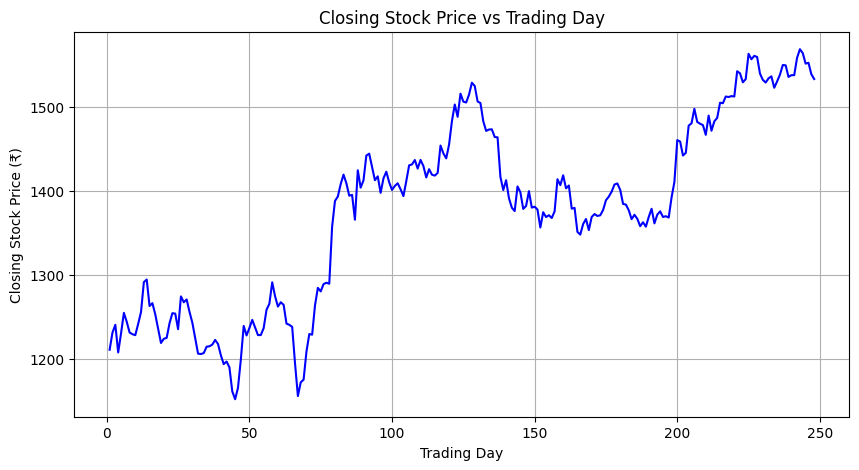

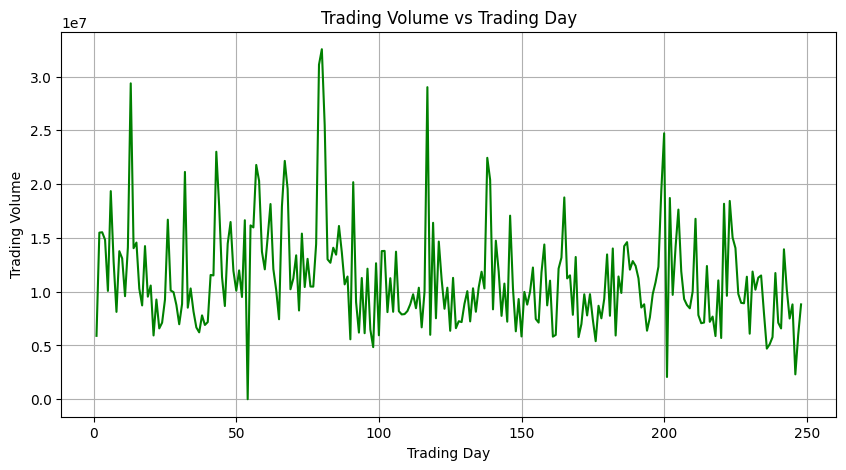

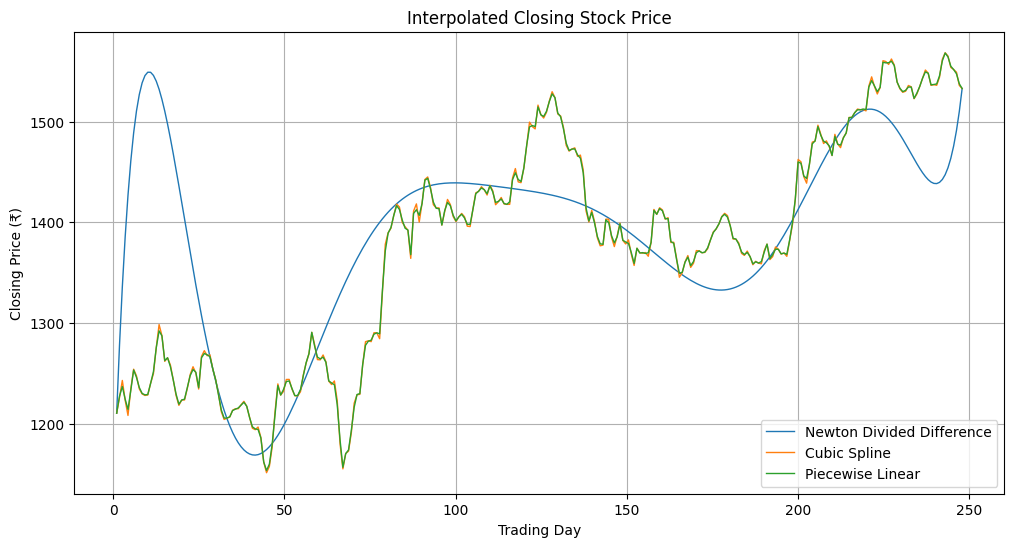

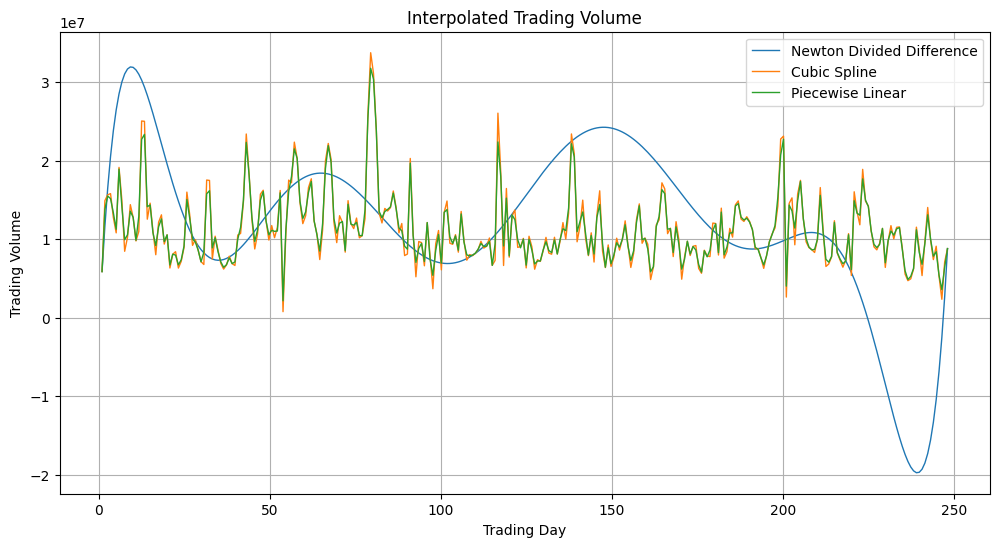

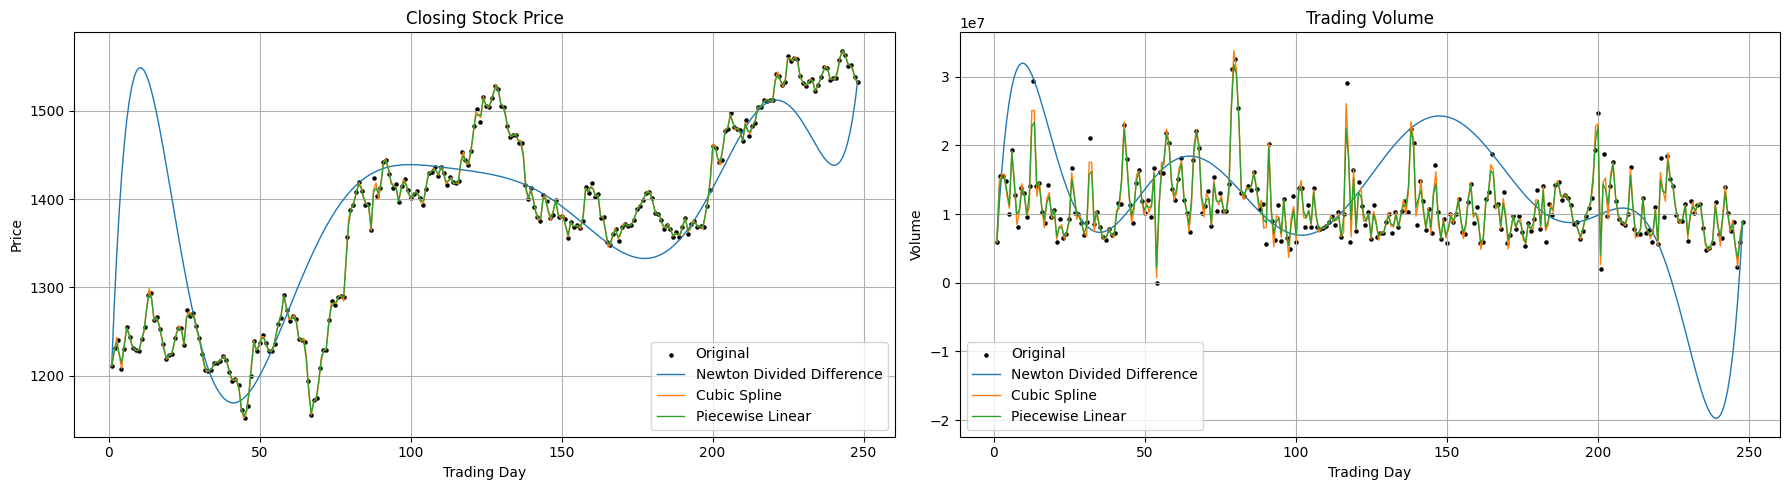

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(t, P, color='blue')
plt.title("Closing Stock Price vs Trading Day")
plt.xlabel("Trading Day")
plt.ylabel("Closing Stock Price (₹)")
plt.grid(True)
plt.show()

# ----------------------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(t, V, color='green')
plt.title("Trading Volume vs Trading Day")
plt.xlabel("Trading Day")
plt.ylabel("Trading Volume")
plt.grid(True)
plt.show()

# ----------------------------------------------------------------------------

plt.figure(figsize=(12, 6))
# plt.scatter(t, P, color='black', s=10, label='Original Data')
plt.plot(t_new_data, P_newton, label='Newton Divided Difference', linewidth=1)
plt.plot(t_new, P_spline, label='Cubic Spline', linewidth=1)
plt.plot(t_new, P_linear, label='Piecewise Linear', linewidth=1)
plt.title("Interpolated Closing Stock Price")
plt.xlabel("Trading Day")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(True)
plt.show()

# ----------------------------------------------------------------------------

plt.figure(figsize=(12, 6))
# plt.scatter(t, V, color='black', s=10, label='Original Data')
plt.plot(t_new_data, V_newton, label='Newton Divided Difference', linewidth=1)
plt.plot(t_new, V_spline, label='Cubic Spline', linewidth=1)
plt.plot(t_new, V_linear, label='Piecewise Linear', linewidth=1)
plt.title("Interpolated Trading Volume")
plt.xlabel("Trading Day")
plt.ylabel("Trading Volume")
plt.legend()
plt.grid(True)
plt.show()

# ----------------------------------------------------------------------------

plt.figure(figsize=(18, 5))

# Closing Price
plt.subplot(1, 2, 1)
plt.scatter(t, P, color='black', s=5, label='Original')
plt.plot(t_new_data, P_newton, label='Newton Divided Difference', linewidth=1)
plt.plot(t_new, P_spline, label='Cubic Spline', linewidth=1)
plt.plot(t_new, P_linear, label='Piecewise Linear', linewidth=1)
plt.title("Closing Stock Price")
plt.xlabel("Trading Day")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

# Trading Volume
plt.subplot(1, 2, 2)
plt.scatter(t, V, color='black', s=5, label='Original')
plt.plot(t_new_data, V_newton, label='Newton Divided Difference', linewidth=1)
plt.plot(t_new, V_spline, label='Cubic Spline', linewidth=1)
plt.plot(t_new, V_linear, label='Piecewise Linear', linewidth=1)
plt.title("Trading Volume")
plt.xlabel("Trading Day")
plt.ylabel("Volume")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


(iv) Using the interpolated values obtained in (ii), perform numerical integration again using:

(a) Trapezoidal Rule

(b) Simpson’s 1/3 Rule

(c) Romberg Integration

In [ ]:
print("Trapezoidal Rule")

# Trapezoidal Rule - Newton's Divided Difference
price_trap_newton = trapezoid(P_newton, x=t_new_data)
volume_trap_newton = trapezoid(V_newton, x=t_new_data)
print("Newton Divided Difference")
print("  Price Integral :", price_trap_newton)
print("  Volume Integral:", volume_trap_newton)

# Trapezoidal Rule - Cubic Spline
price_trap_spline = trapezoid(P_spline, x=t_new)
volume_trap_spline = trapezoid(V_spline, x=t_new)
print("Cubic Spline")
print("  Price Integral :", price_trap_spline)
print("  Volume Integral:", volume_trap_spline)

# Trapezoidal Rule - Piecewise Linear
price_trap_linear = trapezoid(P_linear, x=t_new)
volume_trap_linear = trapezoid(V_linear, x=t_new)
print("Piecewise Linear")
print("  Price Integral :", price_trap_linear)
print("  Volume Integral:", volume_trap_linear)

# ---------------------------------------------------------------------

print("\n","-"*20)
print("Simpson's 1/3 Rule")

# Simpson's 1/3 Rule - Newton's Divided Difference
price_simpson_newton = simpson(P_newton, x=t_new_data)
volume_simpson_newton = simpson(V_newton, x=t_new_data)
print("Newton Divided Difference")
print("  Price Integral :", price_trap_newton)
print("  Volume Integral:", volume_trap_newton)

# Simpson's 1/3 Rule - Cubic Spline
price_simpson_spline = simpson(P_spline, x=t_new)
volume_simpson_spline = simpson(V_spline, x=t_new)
print("Cubic Spline")
print("  Price Integral :", price_simpson_spline)
print("  Volume Integral:", volume_simpson_spline)

# Simpson's 1/3 Rule - Piecewise Linear
price_simpson_linear = simpson(P_linear, x=t_new)
volume_simpson_linear = simpson(V_linear, x=t_new)
print("Piecewise Linear")
print("  Price Integral :", price_simpson_linear)
print("  Volume Integral:", volume_simpson_linear)

# ---------------------------------------------------------------------

# Romberg Integration --> Num samples = 2^k + 1

t_romb = np.linspace(t.min(), t.max(), 257)
t_romb_data = np.linspace(t_.min(), t_.max(), 9)

price_newton_romb = price_newton(t_romb_data)
volume_newton_romb = volume_newton(t_romb_data)

price_spline_romb = price_spline(t_romb)
volume_spline_romb = volume_spline(t_romb)

price_linear_romb = price_linear(t_romb)
volume_linear_romb = volume_linear(t_romb)

dx = t_romb[1] - t_romb[0]
dx_ = t_romb_data[1] - t_romb_data[0]

print("\n","-"*20)
print("Romberg Integration")

price_romb_newton = romb(price_newton_romb, dx=dx_)
volume_romb_newton = romb(volume_newton_romb, dx=dx_)
print("Newton Divided Difference")
print("  Price Integral :", price_romb_newton)
print("  Volume Integral:", volume_romb_newton)

price_romb_spline = romb(price_spline_romb, dx=dx)
volume_romb_spline = romb(volume_spline_romb, dx=dx)
print("Cubic Spline")
print("  Price Integral :", price_romb_spline)
print("  Volume Integral:", volume_romb_spline)

price_romb_linear = romb(price_linear_romb, dx=dx)
volume_romb_linear = romb(volume_linear_romb, dx=dx)
print("Piecewise Linear")
print("  Price Integral :", price_romb_linear)
print("  Volume Integral:", volume_romb_linear)

Trapezoidal Rule
Newton Divided Difference
  Price Integral : 342957.453495253
  Volume Integral: 2973320565.32924
Cubic Spline
  Price Integral : 339771.76518413477
  Volume Integral: 2774942416.251248
Piecewise Linear
  Price Integral : 339767.0435358347
  Volume Integral: 2777186026.565218

 --------------------
Simpson's 1/3 Rule
Newton Divided Difference
  Price Integral : 342957.453495253
  Volume Integral: 2973320565.32924
Cubic Spline
  Price Integral : 339773.7738446159
  Volume Integral: 2786410642.3348074
Piecewise Linear
  Price Integral : 339770.99288521224
  Volume Integral: 2795367617.5092945

 --------------------
Romberg Integration
Newton Divided Difference
  Price Integral : 340830.7081603127
  Volume Integral: 2959194204.866886
Cubic Spline
  Price Integral : 339745.7317955711
  Volume Integral: 2738823189.079097
Piecewise Linear
  Price Integral : 339750.8609822519
  Volume Integral: 2742750513.045338



(v) Compare the results obtained before and after interpolation using:

(a) Absolute error

(b) Relative percentage error

(c) RMSE analysis

(d) Correlation coefficient analysis

In [ ]:
import pandas as pd
import numpy as np

def absolute_error(original, predicted):
    return np.mean(np.abs(original - predicted))

def relative_error(original, predicted):
    return np.mean(np.abs(original - predicted) /
                   np.maximum(np.abs(original), 1e-12)) * 100

def rmse(original, predicted):
    return np.sqrt(np.mean((original - predicted) ** 2))

def correlation_coefficient(original, predicted):
    return np.corrcoef(original, predicted)[0, 1]



# Test points
mask = np.ones(len(t), dtype=bool)
mask[indices] = False  # indices -> selected indices for newton's divided diff
t_test = t[mask]
P_test = P[mask]
V_test = V[mask]

# Newton Predictions
P_newton_pred = price_newton(t_test)
V_newton_pred = volume_newton(t_test)

# Spline Predictions
P_spline_pred = price_spline(t)
V_spline_pred = volume_spline(t)

# Linear Predictions
P_linear_pred = price_linear(t)
V_linear_pred = volume_linear(t)


# ---------------------------------------------------------
# Price Error Analysis
# ---------------------------------------------------------
price_error_analysis = pd.DataFrame({
    "Method": [
        "Newton's Divided Difference",
        "Cubic Spline",
        "Piecewise Linear"
    ],

    "Absolute Error": [
        absolute_error(P_test, P_newton_pred),
        absolute_error(P, P_spline_pred),
        absolute_error(P, P_linear_pred)
    ],

    "Relative Error (%)": [
        relative_error(P_test, P_newton_pred),
        relative_error(P, P_spline_pred),
        relative_error(P, P_linear_pred)
    ],

    "RMSE": [
        rmse(P_test, P_newton_pred),
        rmse(P, P_spline_pred),
        rmse(P, P_linear_pred)
    ],

    "Correlation Coefficient": [
        correlation_coefficient(P_test, P_newton_pred),
        correlation_coefficient(P, P_spline_pred),
        correlation_coefficient(P, P_linear_pred)
    ]
})

# ---------------------------------------------------------
# Volume Error Analysis
# ---------------------------------------------------------
volume_error_analysis = pd.DataFrame({
    "Method": [
        "Newton's Divided Difference",
        "Cubic Spline",
        "Piecewise Linear"
    ],

    "Absolute Error": [
        absolute_error(V_test, V_newton_pred),
        absolute_error(V, V_spline_pred),
        absolute_error(V, V_linear_pred)
    ],

    "Relative Error (%)": [
        relative_error(V_test, V_newton_pred),
        relative_error(V, V_spline_pred),
        relative_error(V, V_linear_pred)
    ],

    "RMSE": [
        rmse(V_test, V_newton_pred),
        rmse(V, V_spline_pred),
        rmse(V, V_linear_pred)
    ],

    "Correlation Coefficient": [
        correlation_coefficient(V_test, V_newton_pred),
        correlation_coefficient(V, V_spline_pred),
        correlation_coefficient(V, V_linear_pred)
    ]
})

print("** Price Error Analysis **")
print(price_error_analysis)

print("\n** Volume Error Analysis **")
print(volume_error_analysis)

** Price Error Analysis **
                        Method  Absolute Error  Relative Error (%)       RMSE  \
0  Newton's Divided Difference       56.437328            4.258537  87.077586   
1                 Cubic Spline        0.000000            0.000000   0.000000   
2             Piecewise Linear        0.000000            0.000000   0.000000   

   Correlation Coefficient  
0                 0.650633  
1                 1.000000  
2                 1.000000  

** Volume Error Analysis **
                        Method  Absolute Error  Relative Error (%)  \
0  Newton's Divided Difference    7.793581e+06        6.598890e+18   
1                 Cubic Spline    0.000000e+00        0.000000e+00   
2             Piecewise Linear    0.000000e+00        0.000000e+00   

           RMSE  Correlation Coefficient  
0  1.044475e+07                 0.172985  
1  0.000000e+00                 1.000000  
2  0.000000e+00                 1.000000  


(vii) Validate the obtained results statistically and provide suitable conclusions regarding the effectiveness of interpolation and numerical integration methods in financial data analysis.

Cubic Spline interpolation gave the smoothest and most stable results, making it a better interpolation method for this stock market dataset.
Newton's Divided Difference worked well with a small number of points, but using too many points can lead to hvery high degree polynomial. So validated it by selecting minial points. Piecewise Linear interpolation was simple and preserved the overall trend.

## Q1

1.
Obtain hourly Air Quality Index (AQI) data for any one major Indian city or the period January 1,
2025 to December 31, 2025 from the CPCB Open Data Portal available at:

https://airquality.cpcb.gov.in/ccr/#/

Use hourly AQI observations (24 observations per day) for the entire year 2025.

In [ ]:
import os
import re
import pandas as pd

folder_path = "/content/drive/MyDrive/Math Modelling lab/AQI_dataset"

aqi_data = []

for file in sorted(os.listdir(folder_path)):

    # Read the Excel file
    df = pd.read_excel(os.path.join(folder_path, file))

    # Extract year and month from filename (e.g., 2025_01)
    match = re.search(r"(\d{4})_(\d{2})", file)
    year = match.group(1)
    month = match.group(2)

    # Get all hourly columns (everything except Date)
    hour_cols = [col for col in df.columns if col != "Date"]

    # Convert from wide format to long format
    df_long = df.melt(
        id_vars="Date",
        value_vars=hour_cols,
        var_name="Hour",
        value_name="AQI"
    )

    # Create full DateTime
    df_long["DateTime"] = pd.to_datetime(
        df_long["Date"].astype(str)
        + "-" + month
        + "-" + year
        + " "
        + df_long["Hour"].astype(str),
        format="%d-%m-%Y %H:%M:%S"
    )

    # Keep only required columns
    df_long = df_long[["DateTime", "AQI"]]

    # Convert AQI to numeric
    df_long["AQI"] = pd.to_numeric(df_long["AQI"], errors="coerce")

    # Store dataframe
    aqi_data.append(df_long)

# Combine all months
aqi_df = pd.concat(aqi_data, ignore_index=True)

# Sort chronologically
aqi_df.sort_values("DateTime", inplace=True)
aqi_df.reset_index(drop=True, inplace=True)

print("Total observations:", len(aqi_df))
print("Missing values:", aqi_df["AQI"].isna().sum())

aqi_df.head()

Total observations: 8664
Missing values: 1734


,DateTime,AQI
0,2025-01-04 00:00:00,NaN
1,2025-01-04 01:00:00,NaN
2,2025-01-04 02:00:00,NaN
3,2025-01-04 03:00:00,NaN
4,2025-01-04 04:00:00,NaN


In [ ]:
aqi_df = aqi_df.sort_values('DateTime').reset_index(drop=True)

# Ensure AQI is numeric
aqi_df["AQI"] = pd.to_numeric(aqi_df["AQI"], errors="coerce")

# Fill existing missing values in the original dataset
aqi_df["AQI"] = (
    aqi_df["AQI"]
    .interpolate(method="linear")
    .bfill()
    .ffill()
)

print(f"Total observations: {len(aqi_df)}")
print(f"Missing values after cleaning: {aqi_df['AQI'].isna().sum()}")

Total observations: 8664
Missing values after cleaning: 0


I. Randomly generate 500 missing observations from the hourly AQI values such that:

A. the missing observations are distributed across different months,

B. at least 100 missing values occur during high pollution periods (AQI > 200).


In [ ]:
import numpy as np

aqi_original = aqi_df.copy()

# Ensure 'AQI' column is used for finding high pollution periods
high_pollution = aqi_df[aqi_df['AQI'] > 200].index

np.random.seed(42)
high_missing = np.random.choice(
    high_pollution,
    size=100,
    replace=False
)

# Use the entire original AQI DataFrame index for remaining points
remaining = aqi_df.index.difference(high_missing)
other_missing = np.random.choice(
    remaining,
    size=400,
    replace=False
)

missing_indices = np.concatenate([high_missing, other_missing])

aqi_missing = aqi_df.copy()
aqi_missing.loc[missing_indices, 'AQI'] = np.nan

# Display some information about the generated missing values
print(f"Total missing values generated: {aqi_missing['AQI'].isna().sum()}")
print("AQI data with generated missing values (first 5 rows):")
print(aqi_missing.head())

Total missing values generated: 500
AQI data with generated missing values (first 5 rows):
             DateTime    AQI
0 2025-01-04 00:00:00  125.0
1 2025-01-04 01:00:00  125.0
2 2025-01-04 02:00:00  125.0
3 2025-01-04 03:00:00  125.0
4 2025-01-04 04:00:00  125.0


II. Reconstruct the missing AQI values using the following interpolation techniques:

A. Linear Interpolation

B. Cubic Spline Interpolation

C. Bézier Curve Interpolation



In [ ]:
# A. Linear Interpolation
aqi_linear_interp = aqi_missing.copy()
aqi_linear_interp['AQI'] = aqi_linear_interp['AQI'].interpolate(method='linear')

print("AQI data after Linear Interpolation (first 5 rows with previously missing values):")
print(aqi_linear_interp[aqi_missing['AQI'].isna()].head())


# B. Cubic Spline Interpolation
aqi_spline_interp = aqi_missing.copy()
aqi_spline_interp["AQI"] = aqi_spline_interp["AQI"].interpolate(method="cubicspline")

print("\n\nAQI data after Cubic Spline Interpolation:")
print(aqi_spline_interp[aqi_missing["AQI"].isna()].head())


# C. Bézier Curve Interpolation
aqi_bezier_interp = aqi_missing.copy()
y = aqi_bezier_interp["AQI"].values.copy()
missing_idx = np.where(np.isnan(y))[0]

for idx in missing_indices:
    # Find previous known value
    left = idx - 1
    while left >= 0 and np.isnan(y[left]):
        left -= 1
    # Find next known values
    right = idx + 1
    while right < len(y) and np.isnan(y[right]):
        right += 1

    if left >= 0 and right < len(y):
        P0 = y[left]
        P3 = y[right]
        P1 = P0
        P2 = P3
        t = (idx-left)/(right-left)
    y[idx] = (1-t)**3 * P0 + 3*(1-t)**2*t * P1 + 3*(1-t)*t**2 * P2 + t**3 * P3
aqi_bezier_interp["AQI"] = y

print("\n\nAQI data after Bézier Curve Interpolation:")
print(aqi_bezier_interp[aqi_missing["AQI"].isna()].head())

AQI data after Linear Interpolation (first 5 rows with previously missing values):
              DateTime    AQI
14 2025-01-04 14:00:00  132.5
19 2025-01-04 19:00:00  128.0
37 2025-01-05 13:00:00  140.5
76 2025-01-07 04:00:00  137.0
80 2025-01-07 08:00:00  158.5


AQI data after Cubic Spline Interpolation:
              DateTime         AQI
14 2025-01-04 14:00:00  133.002916
19 2025-01-04 19:00:00  127.398137
37 2025-01-05 13:00:00  140.802389
76 2025-01-07 04:00:00  136.747030
80 2025-01-07 08:00:00  158.893498


AQI data after Bézier Curve Interpolation:
              DateTime    AQI
14 2025-01-04 14:00:00  132.5
19 2025-01-04 19:00:00  128.0
37 2025-01-05 13:00:00  140.5
76 2025-01-07 04:00:00  137.0
80 2025-01-07 08:00:00  158.5


III. Plot the following graphs:

A. Original AQI vs AQI with missing values

B. Original AQI vs reconstructed AQI for all interpolation methods

C. Error distribution plots for each interpolation technique

D. Scatter plot comparing actual AQI values and interpolated AQI values

E. Zoomed-in plots for pollution peak intervals


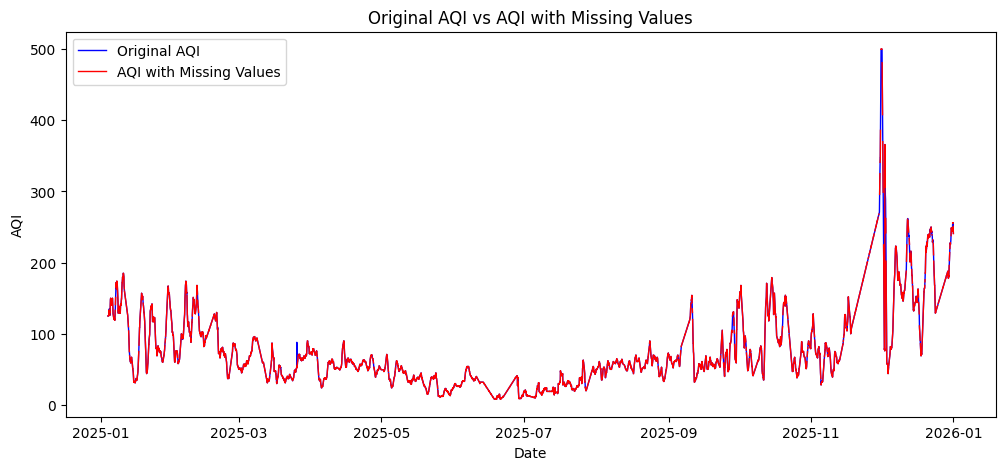

In [ ]:
# III. Plot the following graphs:

import matplotlib.pyplot as plt
import seaborn as sns

# A. Original AQI vs AQI with missing values
plt.figure(figsize=(12,5))
plt.plot(aqi_original["DateTime"], aqi_original["AQI"], label="Original AQI", color="blue", linewidth=1)
plt.plot(aqi_missing["DateTime"], aqi_missing["AQI"], label="AQI with Missing Values", color="red", linewidth=1)
plt.title("Original AQI vs AQI with Missing Values")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.show()

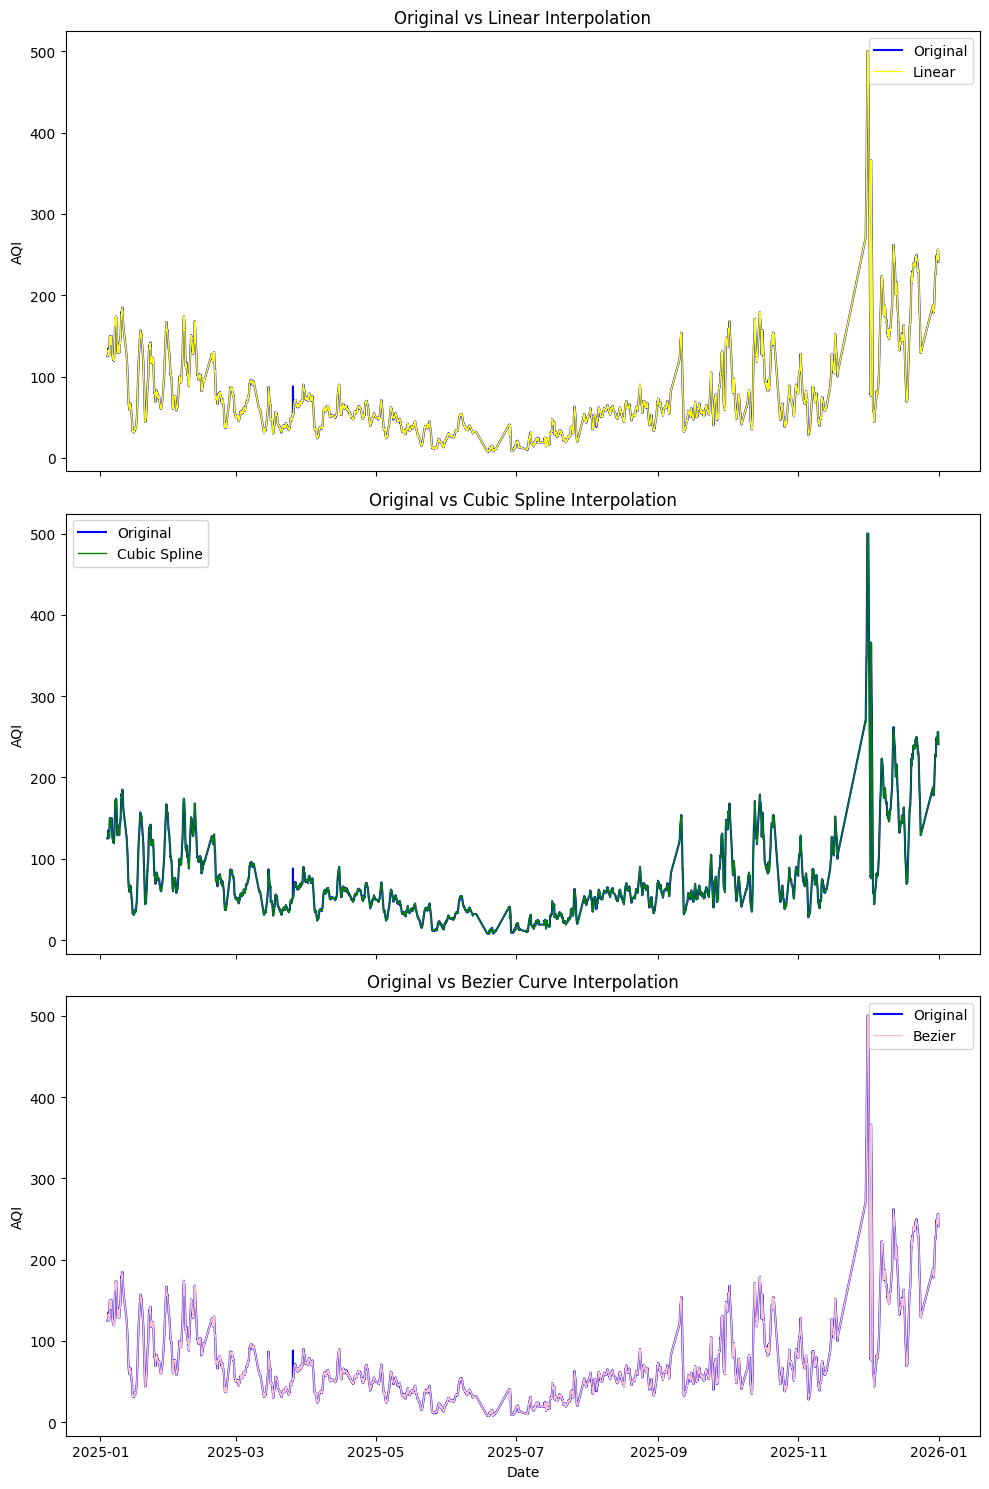

In [ ]:
# B. Original AQI vs reconstructed AQI for all interpolation methods
fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

# Original vs Linear
axes[0].plot(aqi_original["DateTime"], aqi_original["AQI"], color="blue", linewidth=1.5, label="Original")
axes[0].plot(aqi_linear_interp["DateTime"], aqi_linear_interp["AQI"], color="yellow", linewidth=1, label="Linear")
axes[0].set_title("Original vs Linear Interpolation")
axes[0].set_ylabel("AQI")
axes[0].legend()

# Original vs Cubic Spline
axes[1].plot(aqi_original["DateTime"], aqi_original["AQI"], color="blue", linewidth=1.5, label="Original")
axes[1].plot(aqi_spline_interp["DateTime"], aqi_spline_interp["AQI"], color="green", linewidth=1, label="Cubic Spline")
axes[1].set_title("Original vs Cubic Spline Interpolation")
axes[1].set_ylabel("AQI")
axes[1].legend()

# Original vs Bezier
axes[2].plot(aqi_original["DateTime"], aqi_original["AQI"], color="blue", linewidth=1.5, label="Original")
axes[2].plot(aqi_bezier_interp["DateTime"], aqi_bezier_interp["AQI"], color="pink", linewidth=1, label="Bezier")
axes[2].set_title("Original vs Bezier Curve Interpolation")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("AQI")
axes[2].legend()

plt.tight_layout()
plt.show()

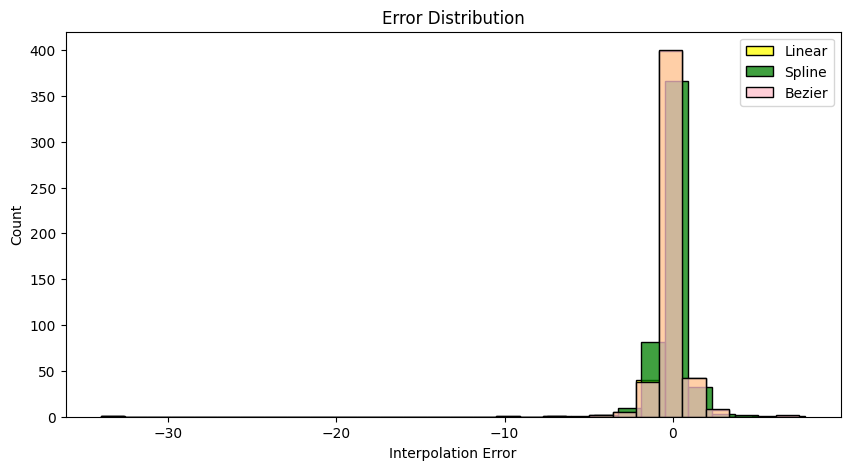

In [ ]:
# C. Error distribution plots for each interpolation technique

missing_mask = aqi_missing["AQI"].isna()

linear_error = (
    aqi_linear_interp.loc[missing_mask, "AQI"]
    - aqi_original.loc[missing_mask, "AQI"]
)

spline_error = (
    aqi_spline_interp.loc[missing_mask, "AQI"]
    - aqi_original.loc[missing_mask, "AQI"]
)

bezier_error = (
    aqi_bezier_interp.loc[missing_mask, "AQI"]
    - aqi_original.loc[missing_mask, "AQI"]
)


plt.figure(figsize=(10,5))
sns.histplot(linear_error, bins=30, label="Linear", color="yellow")
sns.histplot(spline_error, bins=30, label="Spline", color="green")
sns.histplot(bezier_error, bins=30, label="Bezier", color="pink")
plt.title("Error Distribution")
plt.xlabel("Interpolation Error")
plt.legend()
plt.show()

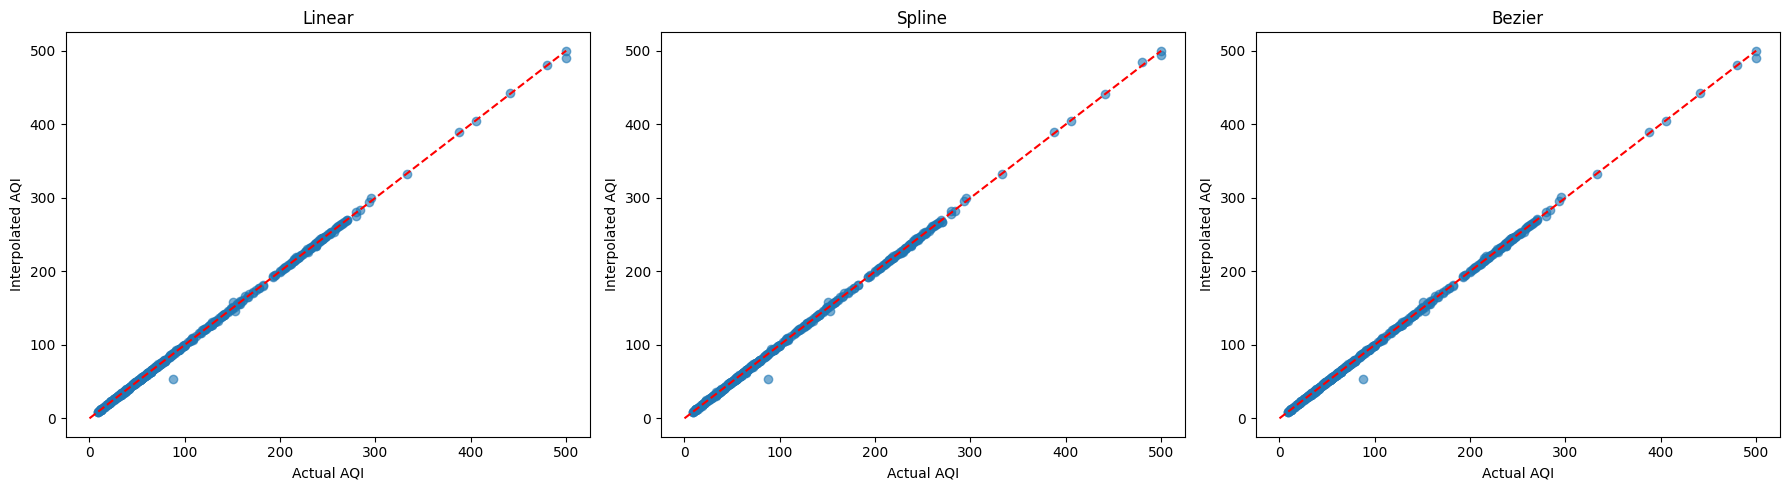

In [ ]:
# D. Scatter plot comparing actual AQI values and interpolated AQI values
# Note: If interpolation was perfect then Interpolated AQI = Actual AQI (y=x)

fig, ax = plt.subplots(1,3, figsize=(18,5))

ax[0].scatter(
    aqi_original.loc[missing_mask,"AQI"],
    aqi_linear_interp.loc[missing_mask,"AQI"],
    alpha=0.6
)
ax[0].plot([0,500],[0,500],'r--')
ax[0].set_title("Linear")

ax[1].scatter(
    aqi_original.loc[missing_mask,"AQI"],
    aqi_spline_interp.loc[missing_mask,"AQI"],
    alpha=0.6
)
ax[1].plot([0,500],[0,500],'r--')
ax[1].set_title("Spline")

ax[2].scatter(
    aqi_original.loc[missing_mask,"AQI"],
    aqi_bezier_interp.loc[missing_mask,"AQI"],
    alpha=0.6
)
ax[2].plot([0,500],[0,500],'r--')
ax[2].set_title("Bezier")

for a in ax:
    a.set_xlabel("Actual AQI")
    a.set_ylabel("Interpolated AQI")

plt.tight_layout()
plt.show()

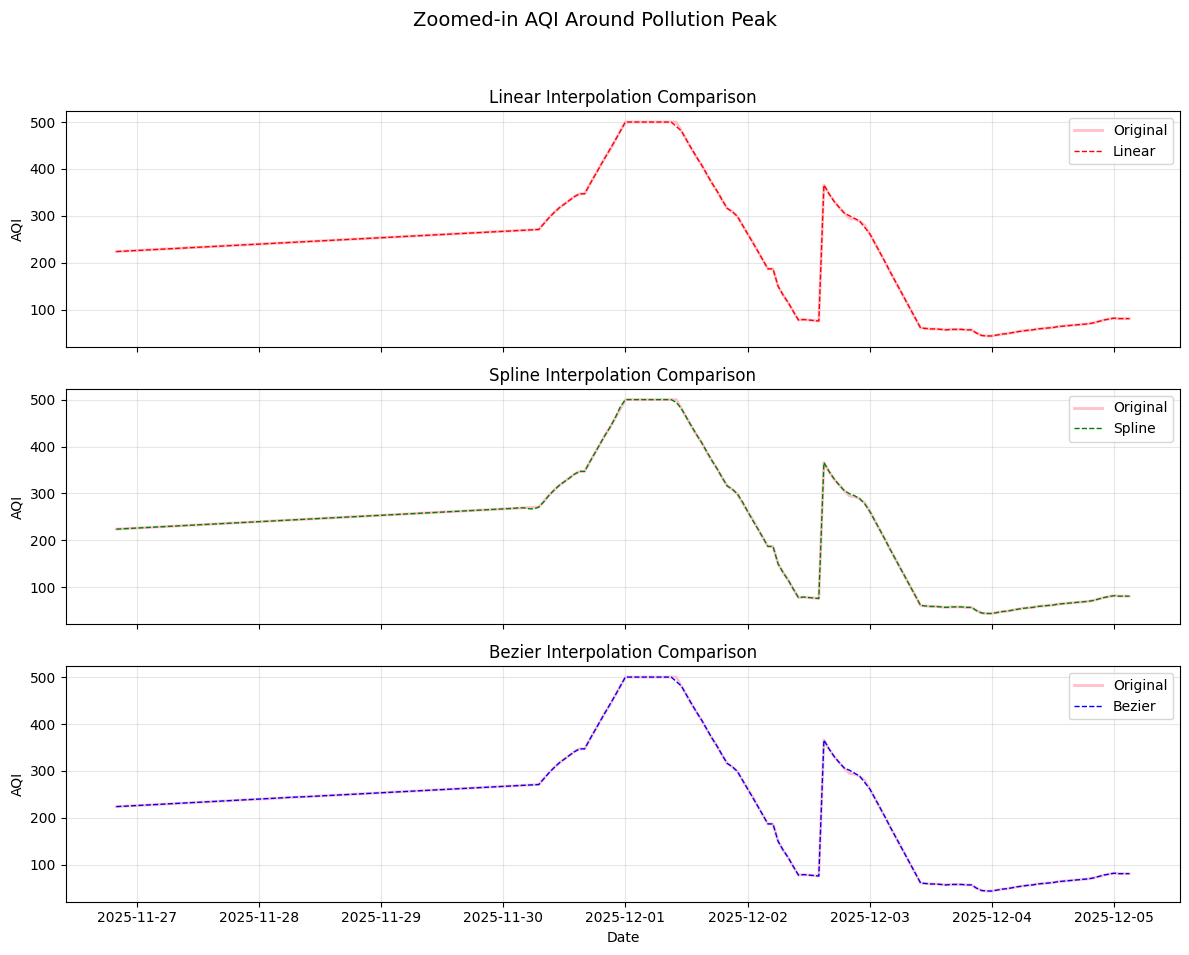

In [ ]:
# E. Zoomed-in plots for pollution peak intervals
peak = aqi_original["AQI"].idxmax()

start = max(0, peak-100)
end = min(len(aqi_original), peak+100)

pfig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# --- Subplot 1: Original vs Linear ---
axes[0].plot(aqi_original["DateTime"].iloc[start:end], aqi_original["AQI"].iloc[start:end],
             label="Original", color='pink', linewidth=2)
axes[0].plot(aqi_linear_interp["DateTime"].iloc[start:end], aqi_linear_interp["AQI"].iloc[start:end],
             label="Linear", color='red', linewidth=1, linestyle='--')
axes[0].set_title("Linear Interpolation Comparison")
axes[0].set_ylabel("AQI")
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# --- Subplot 2: Original vs Spline ---
axes[1].plot(aqi_original["DateTime"].iloc[start:end], aqi_original["AQI"].iloc[start:end],
             label="Original", color='pink', linewidth=2)
axes[1].plot(aqi_spline_interp["DateTime"].iloc[start:end], aqi_spline_interp["AQI"].iloc[start:end],
             label="Spline", color='green', linewidth=1, linestyle='--')
axes[1].set_title("Spline Interpolation Comparison")
axes[1].set_ylabel("AQI")
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# --- Subplot 3: Original vs Bezier ---
axes[2].plot(aqi_original["DateTime"].iloc[start:end], aqi_original["AQI"].iloc[start:end],
             label="Original", color='pink', linewidth=2)
axes[2].plot(aqi_bezier_interp["DateTime"].iloc[start:end], aqi_bezier_interp["AQI"].iloc[start:end],
             label="Bezier", color='blue', linewidth=1, linestyle='--')
axes[2].set_title("Bezier Interpolation Comparison")
axes[2].set_ylabel("AQI")
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

axes[2].set_xlabel("Date")
pfig.suptitle("Zoomed-in AQI Around Pollution Peak", fontsize=14)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
plt.show()

IV. Compare the interpolation methods during:

A. High pollution intervals (AQI > 200)

B. Moderate pollution intervals (AQI between 100 and 200)

C. Low pollution intervals (AQI < 100)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

# Locations where values were artificially removed
missing_mask = aqi_missing["AQI"].isna()

# Actual AQI values (ground truth)
actual = aqi_original.loc[missing_mask, "AQI"]

# Interpolated values
linear_pred = aqi_linear_interp.loc[missing_mask, "AQI"]
spline_pred = aqi_spline_interp.loc[missing_mask, "AQI"]
bezier_pred = aqi_bezier_interp.loc[missing_mask, "AQI"]


# Pollution categories based on actual AQI
pollution_category = pd.cut(
    actual,
    bins=[-np.inf, 100, 200, np.inf],
    labels=[
        "Low (AQI < 100)",
        "Moderate (100-200)",
        "High (AQI > 200)"
    ]
)
pollution_category.value_counts()

,count
AQI,
Low (AQI < 100),307
High (AQI > 200),108
Moderate (100-200),85


In [ ]:
def calculate_metrics(actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    corr, _ = pearsonr(actual, predicted)
    return rmse, mae, corr


results = []
methods = {
    "Linear": linear_pred,
    "Cubic Spline": spline_pred,
    "Bezier": bezier_pred
}

for category in pollution_category.unique():
    mask = pollution_category == category
    for method_name, prediction in methods.items():
        rmse, mae, corr = calculate_metrics(
            actual[mask],
            prediction[mask]
        )
        results.append([category, method_name, rmse, mae, corr])

comparison_df = pd.DataFrame(
    results,
    columns=["Pollution Level", "Method", "RMSE", "MAE", "Pearson Correlation"]
  )
comparison_df

,Pollution Level,Method,RMSE,MAE,Pearson Correlation
0,Moderate (100-200),Linear,1.397944,0.709804,0.998382
1,Moderate (100-200),Cubic Spline,1.388447,0.645520,0.998411
2,Moderate (100-200),Bezier,1.404415,0.727298,0.998364
3,Low (AQI < 100),Linear,2.011964,0.472856,0.996186
4,Low (AQI < 100),Cubic Spline,2.035327,0.538558,0.996095
5,Low (AQI < 100),Bezier,2.013355,0.477403,0.996182
6,High (AQI > 200),Linear,1.440477,0.628086,0.999666
7,High (AQI > 200),Cubic Spline,1.301958,0.682018,0.999721
8,High (AQI > 200),Bezier,1.502044,0.672356,0.999634


V. Validate the interpolation methods statistically using:

A. Root Mean Square Error (RMSE)

B. Mean Absolute Error (MAE)

C. Pearson Correlation Coefficient

D. Residual Error Analysis

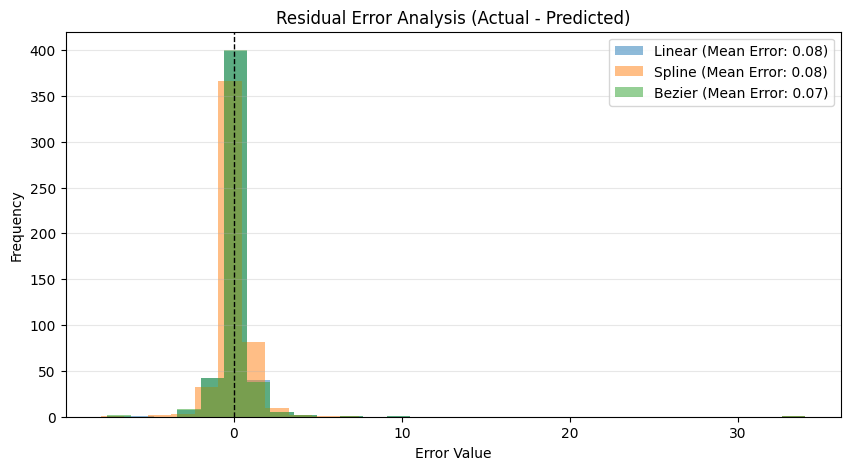

,Method,RMSE,MAE,Pearson Corr,Mean Residual,Std. Residual
0,Linear,1.807177,0.546667,0.999782,0.083000,1.805270
1,Spline,1.799276,0.587729,0.999784,0.079167,1.797533
2,Bezier,1.819764,0.561995,0.999779,0.071927,1.818342


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

preds = {"Linear": linear_pred, "Spline": spline_pred, "Bezier": bezier_pred}
stats = []

plt.figure(figsize=(10, 5))

for name, pred in preds.items():
    residual = actual - pred
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    corr, _ = pearsonr(actual, pred)

    stats.append([name, rmse, mae, corr, np.mean(residual), np.std(residual)])
    plt.hist(residual, bins=30, alpha=0.5, label=f"{name} (Mean Error: {np.mean(residual):.2f})")

plt.axvline(0, color='black', linestyle='dashed', linewidth=1)
plt.title("Residual Error Analysis (Actual - Predicted)")
plt.xlabel("Error Value")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Display the Table
df_results = pd.DataFrame(stats, columns=["Method", "RMSE", "MAE", "Pearson Corr", "Mean Residual", "Std. Residual"])
df_results